# 09 黑马优购 - 购物车页面与收货地址


本篇是微信小程序**项目第 4 天**，承接 08 的加入购物车，按包内讲义“9. 购物车页面”的顺序完成商品列表、勾选状态、数量输入、滑动删除，再封装收货地址组件，处理本地保存和重新授权。

资料来自[课程网盘](https://pan.baidu.com/s/1crZTQdIZ7OSDkZIpIWkhYw?pwd=1234)中的“微信小程序项目/微信小程序项目-资料/day04.rar”，本机下载文件为 `day04 (2).rar`。本篇已读取包内学习目标、20 页 `uni-shop_day4.pdf` 和 `代码/uni-shop-2` 源码；清晰图片和代码块对照同课程[购物车在线讲义](https://applet-base-api-t.itheima.net/docs-uni-shop/9.cart.html)，内容截至 **9.2.9**。教学图片直接内嵌在 Notebook 中。

包内学习目标：为 `my-goods` 封装 radio 勾选状态和 NumberBox，实现购物车滑动删除，封装收货地址组件，实现收货地址重新授权。项目沿用 Vue 2、Vuex 和包内旧版 uni-ui 的写法。

| 文件 | 本天用途 |
| --- | --- |
| `pages/cart/cart.vue` | 显示购物车商品、监听子组件事件、调用 mutation |
| `components/my-goods/my-goods.vue` | 按需显示 radio 和 NumberBox，向父页面传递变更 |
| `components/uni-number-box/uni-number-box.vue` | 修正失焦转换和 `inputValue` 侦听条件 |
| `store/cart.js` | 修改勾选状态、修改数量、删除商品并保存 |
| `components/my-address/my-address.vue` | 地址选择、信息显示、重新授权 |
| `store/user.js`、`store/store.js` | 保存地址、拼接详细地址、挂载 `m_user` |
| `static/cart_border@2x.png` | 收货地址下方的装饰边框，来自项目素材 |

购物车开发承接 08 的 `cart` 分支。下面的代码和操作用于跟课阅读；本笔记不会执行这些教学代码。


## 9.0 创建购物车页面的编译模式

打开微信开发者工具，点击工具栏的“编译模式”下拉菜单，选择“添加编译模式”。

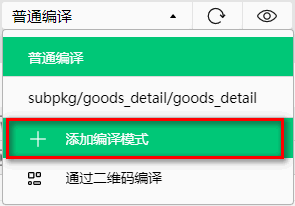


模式名称和启动页面都填写 `pages/cart/cart`，启动参数留空，确认后选择该模式编译。这样每次编译直接进入购物车页面，便于调试当前功能。

调试前先在商品详情页向购物车加入几件商品；列表数据从 08 已配置好的 Vuex 和本地 `cart` 缓存读取，本天不再请求商品列表接口。

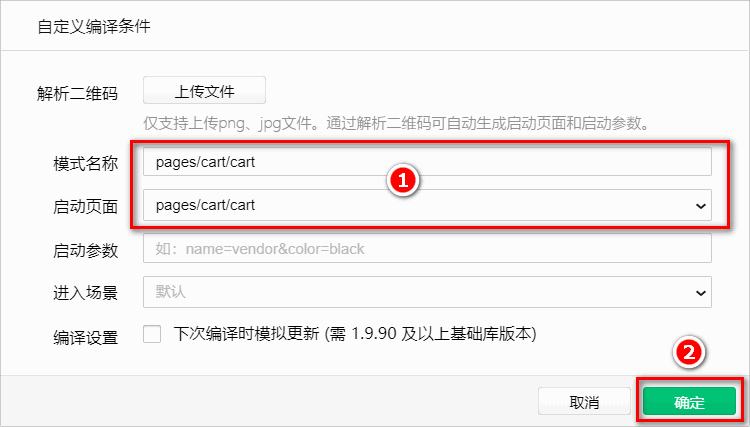


## 9.1 商品列表区域

### 9.1.1 渲染购物车商品列表的标题区域

在 `pages/cart/cart.vue` 的根 `<view>` 中放入商店图标和“购物车”文字：

```html
<!-- 购物车商品列表的标题区域 -->
<view class="cart-title">
  <!-- 左侧的图标 -->
  <uni-icons type="shop" size="18"></uni-icons>
  <!-- 描述文本 -->
  <text class="cart-title-text">购物车</text>
</view>
```

在同文件 `<style lang="scss">` 中添加标题样式：

```scss
.cart-title {
  height: 40px;
  display: flex;
  align-items: center;
  font-size: 14px;
  padding-left: 5px;
  border-bottom: 1px solid #efefef;
  .cart-title-text {
    margin-left: 10px;
  }
}
```

标题高 40px，图标和文字横向居中对齐，左边留 5px，文字与图标间距 10px，底部加浅色边线。


### 9.1.2 渲染商品列表区域的基本结构

在 `cart.vue` 中保留 08 的 `badgeMix`，导入 `mapState`，将命名空间 `m_cart` 内的 `cart` 映射为页面计算属性：

```javascript
import badgeMix from '@/mixins/tabbar-badge.js'
// 按需导入 mapState 这个辅助函数
import { mapState } from 'vuex'

export default {
  mixins: [badgeMix],
  computed: {
    // 将 m_cart 模块中的 cart 数组映射到当前页面中使用
    ...mapState('m_cart', ['cart']),
  },
  data() {
    return {}
  },
}
```

在标题下循环渲染已有的 `my-goods` 组件：

```html
<!-- 商品列表区域 -->
<block v-for="(goods, i) in cart" :key="i">
  <my-goods :goods="goods"></my-goods>
</block>
```

`block` 负责组织循环，不额外产生布局盒子；`goods` 是当前商品对象。此前加入购物车时，商品已包含 `goods_id`、`goods_name`、`goods_price`、`goods_count`、`goods_small_logo`、`goods_state` 六个字段。

此时应能看到缓存中的商品、默认图片和价格，勾选与数量操作会在接下来的步骤加入。


### 9.1.3 为 my-goods 组件封装 radio 勾选状态

`my-goods` 同时用于普通商品列表和购物车。给它增加 `showRadio`，默认隐藏，只有购物车明确传 `true` 才显示勾选按钮。在 `components/my-goods/my-goods.vue` 的 `props` 中保留 `goods`，加入：

```javascript
export default {
  props: {
    goods: {
      type: Object,
      default: {}
    },
    showRadio: {
      type: Boolean,
      default: false
    }
  }
}
```

讲义先用 `checked` 展示静态选中效果，再改为绑定 `goods.goods_state`。左侧图片区域最终结构如下，后续再增加点击事件：

```html
<!-- 商品左侧图片区域 -->
<view class="goods-item-left">
  <!-- 存储在购物车中的商品，包含 goods_state 属性，表示商品的勾选状态 -->
  <radio :checked="goods.goods_state" color="#C00000" v-if="showRadio"></radio>
  <image :src="goods.goods_small_logo || defaultPic" class="goods-pic"></image>
</view>
```

`checked` 决定是否选中，`color="#C00000"` 指定选中颜色，`v-if="showRadio"` 决定是否渲染按钮。当前商品的 `goods_state` 为布尔值。

把 `.goods-item-left` 改为横向 Flex，使按钮和图片左右排列并垂直居中：

```scss
.goods-item-left {
  margin-right: 5px;
  display: flex;
  justify-content: space-between;
  align-items: center;

  .goods-pic {
    width: 100px;
    height: 100px;
    display: block;
  }
}
```

在 `cart.vue` 的列表中启用显示：

```html
<!-- 商品列表区域 -->
<block v-for="(goods, i) in cart" :key="i">
  <my-goods :goods="goods" :show-radio="true"></my-goods>
</block>
```

组件内部属性用 `showRadio`，模板传参用 `show-radio`；其他页面不传这个属性，仍然只显示原来的商品信息。


### 9.1.4 为 my-goods 组件封装 radio-change 事件

点击 radio 后，子组件把商品 ID 和新的选中状态交给父页面，由父页面修改 Store。这样 `my-goods` 只负责展示和发出变更，不直接改 `goods` 的数据。

先在 `cart.vue` 给 `my-goods` 绑定事件：

```html
<!-- 商品列表区域 -->
<block v-for="(goods, i) in cart" :key="i">
  <!-- 在 radioChangeHandler 事件处理函数中，通过事件对象 e，得到商品的 goods_id 和 goods_state -->
  <my-goods :goods="goods" :show-radio="true" @radio-change="radioChangeHandler"></my-goods>
</block>
```

此阶段可以在父页面 `methods` 中接收并打印事件参数，检查是否同时包含 `goods_id` 和 `goods_state`：

```javascript
export default {
  methods: {
    // 商品的勾选状态发生了变化
    radioChangeHandler(e) {
      console.log(e) // 输出得到的数据 -> {goods_id: 395, goods_state: false}
    }
  }
}
```

在 `my-goods.vue` 的 radio 上绑定点击事件：

```html
<!-- 商品左侧图片区域 -->
<view class="goods-item-left">
  <radio :checked="goods.goods_state" color="#C00000" v-if="showRadio" @click="radioClickHandler"></radio>
  <image :src="goods.goods_small_logo || defaultPic" class="goods-pic"></image>
</view>
```

在子组件的 `methods` 中发出自定义事件：

```javascript
export default {
  methods: {
    // radio 组件的点击事件处理函数
    radioClickHandler() {
      // 通过 this.$emit() 触发外界通过 @ 绑定的 radio-change 事件，
      // 同时把商品的 Id 和 勾选状态 作为参数传递给 radio-change 事件处理函数
      this.$emit('radio-change', {
        // 商品的 Id
        goods_id: this.goods.goods_id,
        // 商品最新的勾选状态
        goods_state: !this.goods.goods_state
      })
    }
  }
}
```

`!this.goods.goods_state` 把当前状态取反，因此已选商品可以取消选择，未选商品可以重新勾选。`radio-change` 的参数是子组件构造的业务对象，与原生点击事件对象不同。


### 9.1.5 修改购物车中商品的勾选状态

在 `store/cart.js` 的 `mutations` 中新增 `updateGoodsState`：

```javascript
export default {
  mutations: {
    // 更新购物车中商品的勾选状态
    updateGoodsState(state, goods) {
      // 根据 goods_id 查询购物车中对应商品的信息对象
      const findResult = state.cart.find(x => x.goods_id === goods.goods_id)

      // 有对应的商品信息对象
      if (findResult) {
        // 更新对应商品的勾选状态
        findResult.goods_state = goods.goods_state
        // 持久化存储到本地
        this.commit('m_cart/saveToStorage')
      }
    }
  }
}
```

`find()` 按 `goods_id` 找到商品，再更新 `goods_state`。找到后调用已有的 `m_cart/saveToStorage` 保存整个购物车；如果商品不存在，则不修改数据。

在 `cart.vue` 中导入 `mapMutations`，把方法映射到页面，并替换刚才的打印逻辑：

```javascript
import badgeMix from '@/mixins/tabbar-badge.js'
import { mapState, mapMutations } from 'vuex'

export default {
  mixins: [badgeMix],
  computed: {
    ...mapState('m_cart', ['cart']),
  },
  data() {
    return {}
  },
  methods: {
    ...mapMutations('m_cart', ['updateGoodsState']),
    // 商品的勾选状态发生了变化
    radioChangeHandler(e) {
      this.updateGoodsState(e)
    },
  },
}
```

完整流程为：点击 radio → 子组件 `$emit('radio-change', {...})` → 页面 `radioChangeHandler(e)` → Store `updateGoodsState` → 本地保存。再次编译进入购物车时，勾选状态应保留。


### 9.1.6 为 my-goods 组件封装 NumberBox

NumberBox 是 uni-ui 提供的带加减按钮的数字输入框，对应项目中的 `uni-number-box`。在 `my-goods.vue` 的 `.goods-info-box` 内，把商品价格和数量输入框放在同一行。

初始用 `:min="1"` 限制最小数量，随后增加 `:value="goods.goods_count"` 读取商品当前数量。给 `props` 新增 `showNum`，默认隐藏：

```javascript
export default {
  // 定义 props 属性，用来接收外界传递到当前组件的数据
  props: {
    // 商品的信息对象
    goods: {
      type: Object,
      default: {},
    },
    // 是否展示图片左侧的 radio
    showRadio: {
      type: Boolean,
      // 如果外界没有指定 show-radio 属性的值，则默认不展示 radio 组件
      default: false,
    },
    // 是否展示价格右侧的 NumberBox 组件
    showNum: {
      type: Boolean,
      default: false,
    },
  },
}
```

> 原讲义此处把 `goods` 的 `default` 拼成了 `defaul`，包内源码使用正确的 `default`，上面已按源码修正。

组件中的数量输入框最终结构如下，`@change` 会在下一节补上事件处理方法：

```html
<view class="goods-info-box">
  <!-- 商品价格 -->
  <view class="goods-price">￥{{goods.goods_price | tofixed}}</view>
  <!-- 商品数量 -->
  <uni-number-box :min="1" :value="goods.goods_count" @change="numChangeHandler" v-if="showNum"></uni-number-box>
</view>
```

修改右侧布局，让商品名称位于上方，价格和数量位于下方并分居两侧：

```scss
.goods-item-right {
  display: flex;
  flex: 1;
  flex-direction: column;
  justify-content: space-between;

  .goods-name {
    font-size: 13px;
  }

  .goods-info-box {
    display: flex;
    align-items: center;
    justify-content: space-between;
  }

  .goods-price {
    font-size: 16px;
    color: #c00000;
  }
}
```

在 `cart.vue` 中传 `:show-num="true"`：

```html
<!-- 商品列表区域 -->
<block v-for="(goods, i) in cart" :key="i">
  <my-goods :goods="goods" :show-radio="true" :show-num="true" @radio-change="radioChangeHandler"></my-goods>
</block>
```

普通商品列表不传 `show-num`，数量框仍然隐藏。`flex: 1` 让右侧盒子占据剩余宽度，`justify-content: space-between` 分开价格与数量。


### 9.1.7 为 my-goods 组件封装 num-change 事件

数量发生变化时，也由子组件传出“商品 ID + 最新数量”。在 `cart.vue` 中加入 `@num-change`：

```html
<!-- 商品列表区域 -->
<block v-for="(goods, i) in cart" :key="i">
  <my-goods :goods="goods" :show-radio="true" :show-num="true" @radio-change="radioChangeHandler" @num-change="numberChangeHandler"></my-goods>
</block>
```

先在页面 `methods` 中用打印检查参数：

```javascript
export default {
  methods: {
    // 商品的数量发生了变化
    numberChangeHandler(e) {
      console.log(e)
    }
  }
}
```

在 `my-goods.vue` 中，给 NumberBox 绑定 `@change="numChangeHandler"`，保留上一节的 `v-if="showNum"`：

```html
<uni-number-box
  :min="1"
  :value="goods.goods_count"
  v-if="showNum"
  @change="numChangeHandler"
></uni-number-box>
```

在子组件 `methods` 中加入：

```javascript
export default {
  methods: {
    // NumberBox 组件的 change 事件处理函数
    numChangeHandler(val) {
      // 通过 this.$emit() 触发外界通过 @ 绑定的 num-change 事件
      this.$emit('num-change', {
        // 商品的 Id
        goods_id: this.goods.goods_id,
        // 商品的最新数量
        goods_count: +val
      })
    }
  }
}
```

NumberBox 的 `change` 参数 `val` 是当前输入值；一元 `+` 将它转成数值，再放入 `goods_count`，避免后续统计时把字符串拼接起来。


### 9.1.8 解决 NumberBox 数据不合法的问题

课程发现，用户在数量框中输入字母等内容，会造成数量数据异常。打开 `components/uni-number-box/uni-number-box.vue`，把 `methods` 中 `_onBlur` 的原始输入转换为整数；转换结果为假值时恢复为 1。

下面依据包内源码保留完整方法，包含讲义省略的最小值和最大值处理。替换对应方法即可，组件其他方法保留：

```javascript
export default {
  methods: {
    _onBlur(event) {
      // let value = event.detail.value;
      let value = parseInt(event.detail.value);
      if (!value) {
        this.inputValue = 1;
        return;
      }
      value = +value;
      if (value > this.max) {
        value = this.max;
      } else if (value < this.min) {
        value = this.min;
      }
      this.inputValue = value;
    }
  }
}
```

输入框失去焦点时，`parseInt()` 截取整数，之后再依据 `this.min` 和 `this.max` 修正范围。项目组件的 `max` 默认是 100，购物车指定 `min` 为 1。

| 输入示例 | 失焦后的课程处理 |
| --- | --- |
| `3.8` | 转为 `3` |
| `abc` 或空字符串 | 转换为 `NaN`，恢复为 `1` |
| `0` | `if (!value)` 同样成立，恢复为 `1` |
| `150` | 超过默认最大值，变成 `100` |

> 原注释把 `if (!value)` 解释成只判断 `NaN`，实际也包含 `0`。`parseInt()` 还可能从 `12abc` 这类字符串截出 `12`，这里记录的是课程的输入修正，不是对所有输入格式的完整校验。


### 9.1.9 完善 NumberBox 的 inputValue 侦听器

只在失焦时修正还不够：输入过程中 `v-model` 会改变 `inputValue`，原侦听器只比较新旧值，就可能提前把字母或小数传给外部。

在同一组件 `watch` 节点中，替换 `inputValue` 侦听器：

```javascript
export default {
  watch: {
    inputValue(newVal, oldVal) {
      // 官方提供的 if 判断条件，在用户每次输入内容时，都会调用 this.$emit("change", newVal)
      // if (+newVal !== +oldVal) {

      // 新旧内容不同 && 新值内容合法 && 新值中不包含小数点
      if (+newVal !== +oldVal && Number(newVal) && String(newVal).indexOf('.') === -1) {
        this.$emit("change", newVal);
      }
    }
  }
}
```

这个条件要求三点同时满足：新旧值按数值比较不同、`Number(newVal)` 为真值、字符串中没有小数点。满足后才 `$emit("change", newVal)`，随后由 `my-goods` 转成数值再传出。

注意它会排除 `0`、`NaN`、空字符串和含小数点的值，但没有在侦听器中直接判断 `min`/`max`；范围修正仍依赖组件的加减逻辑和 `_onBlur`。它也不是严格的正整数格式校验。输入小数时先不外传，失焦转为整数后再按变化条件发出事件。


### 9.1.10 修改购物车中商品的数量

在 `store/cart.js` 的 `mutations` 中新增：

```javascript
export default {
  mutations: {
    // 更新购物车中商品的数量
    updateGoodsCount(state, goods) {
      // 根据 goods_id 查询购物车中对应商品的信息对象
      const findResult = state.cart.find(x => x.goods_id === goods.goods_id)

      if(findResult) {
        // 更新对应商品的数量
        findResult.goods_count = goods.goods_count
        // 持久化存储到本地
        this.commit('m_cart/saveToStorage')
      }
    }
  }
}
```

在 `cart.vue` 的 `mapMutations` 中同时映射状态更新和数量更新，并把 `numberChangeHandler` 的打印改为调用 Store：

```javascript
import badgeMix from '@/mixins/tabbar-badge.js'
import { mapState, mapMutations } from 'vuex'

export default {
  mixins: [badgeMix],
  computed: {
    ...mapState('m_cart', ['cart']),
  },
  data() {
    return {}
  },
  methods: {
    ...mapMutations('m_cart', ['updateGoodsState', 'updateGoodsCount']),
    // 商品的勾选状态发生了变化
    radioChangeHandler(e) {
      this.updateGoodsState(e)
    },
    // 商品的数量发生了变化
    numberChangeHandler(e) {
      this.updateGoodsCount(e)
    },
  },
}
```

页面只负责转交参数。Store 按 ID 找到商品，覆盖其 `goods_count`，再保存本地缓存。点击加减按钮或手动输入后失焦，应看到数量更新；重新编译后，更新结果仍保留。

08 的 `total` getter 已按所有商品的 `goods_count` 求和，本天不需要改它。包内 `badgeMix` 仍在页面 `onShow` 时刷新徽标，不能把数量数据变化等同于当前页面中的徽标立即刷新。


### 9.1.11 渲染滑动删除的 UI 效果

滑动操作需要 uni-ui 的两个组件：`uni-swipe-action` 是外层容器，`uni-swipe-action-item` 为每个商品提供可滑出的操作按钮。项目已包含对应组件，也可在编辑器中使用 `uSwipeAction` 代码块生成基本结构。

把 `cart.vue` 的商品循环改成：

```html
<!-- 商品列表区域 -->
<!-- uni-swipe-action 是最外层包裹性质的容器 -->
<uni-swipe-action>
  <block v-for="(goods, i) in cart" :key="i">
    <!-- uni-swipe-action-item 可以为其子节点提供滑动操作的效果。需要通过 options 属性来指定操作按钮的配置信息 -->
    <uni-swipe-action-item :options="options" @click="swipeActionClickHandler(goods)">
      <my-goods :goods="goods" :show-radio="true" :show-num="true" @radio-change="radioChangeHandler" @num-change="numberChangeHandler"></my-goods>
    </uni-swipe-action-item>
  </block>
</uni-swipe-action>
```

在页面 `data()` 中声明按钮配置，`options` 数组的每项代表一个操作按钮：

```javascript
export default {
  data() {
    return {
      options: [{
        text: '删除', // 显示的文本内容
        style: {
          backgroundColor: '#C00000' // 按钮的背景颜色
        }
      }]
    }
  }
}
```

先在 `methods` 中接收被操作的商品，用于核对点击事件：

```javascript
export default {
  methods: {
    // 点击了滑动操作按钮
    swipeActionClickHandler(goods) {
      console.log(goods)
    }
  }
}
```

此处 `@click` 是滑动操作按钮的事件，模板显式传入当前 `goods`。滑出“删除”后点击，处理函数应能拿到该商品对象。

为避免滑动时商品盒子宽度不一致，在 `my-goods.vue` 中增加整行宽度和盒模型设置：

```scss
.goods-item {
  // 让 goods-item 项占满整个屏幕的宽度
  width: 750rpx;
  // 设置盒模型为 border-box
  box-sizing: border-box;
  display: flex;
  padding: 10px 5px;
  border-bottom: 1px solid #f0f0f0;
}
```

`750rpx` 对应屏幕宽度，`border-box` 把左右 padding 算进这段宽度，避免总宽度额外增加。


### 9.1.12 实现滑动删除的功能

在 `store/cart.js` 的 `mutations` 中新增 `removeGoodsById`：

```javascript
export default {
  mutations: {
    // 根据 Id 从购物车中删除对应的商品信息
    removeGoodsById(state, goods_id) {
      // 调用数组的 filter 方法进行过滤
      state.cart = state.cart.filter(x => x.goods_id !== goods_id)
      // 持久化存储到本地
      this.commit('m_cart/saveToStorage')
    }
  }
}
```

`filter()` 保留 ID 不等于目标 ID 的商品，并把新数组赋给 `state.cart`，最后同步缓存。

在 `cart.vue` 中映射删除方法，并把滑动按钮的处理函数改为删除对应 ID：

```javascript
export default {
  methods: {
    ...mapMutations('m_cart', ['updateGoodsState', 'updateGoodsCount', 'removeGoodsById']),
    // 商品的勾选状态发生了变化
    radioChangeHandler(e) {
      this.updateGoodsState(e)
    },
    // 商品的数量发生了变化
    numberChangeHandler(e) {
      this.updateGoodsCount(e)
    },
    // 点击了滑动操作按钮
    swipeActionClickHandler(goods) {
      this.removeGoodsById(goods.goods_id)
    }
  }
}
```

> 讲义使用 `swipeActionClickHandler`，包内完成版使用 `swipeItemClickHandler`。两者承担相同操作；页面绑定和 `methods` 函数名必须一致。后面的包内源码保留 `swipeItemClickHandler`。

滑动删除后，列表应立即移除目标商品，其他商品仍在；再次编译时，被删除商品不会从缓存恢复。


## 9.2 收货地址区域

### 9.2.1 创建收货地址组件

在 HBuilderX 的 `components` 目录上右键“新建组件”，名称填 `my-address`，勾选使用 scss 和创建同名目录，得到 `components/my-address/my-address.vue`。

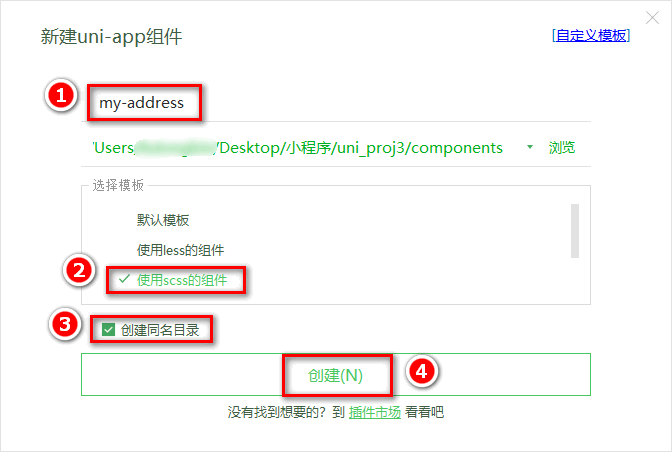


先在组件模板中搭好两个区域：一个显示“请选择收货地址+”按钮，一个显示收货人、电话和详细地址。此阶段用示例文字确认布局：

```html
<view>

  <!-- 选择收货地址的盒子 -->
  <view class="address-choose-box">
    <button type="primary" size="mini" class="btnChooseAddress">请选择收货地址+</button>
  </view>

  <!-- 渲染收货信息的盒子 -->
  <view class="address-info-box">
    <view class="row1">
      <view class="row1-left">
        <view class="username">收货人：<text>escook</text></view>
      </view>
      <view class="row1-right">
        <view class="phone">电话：<text>138XXXX5555</text></view>
        <uni-icons type="arrowright" size="16"></uni-icons>
      </view>
    </view>
    <view class="row2">
      <view class="row2-left">收货地址：</view>
      <view class="row2-right">河北省邯郸市肥乡区xxx 河北省邯郸市肥乡区xxx 河北省邯郸市肥乡区xxx 河北省邯郸市肥乡区xxx </view>
    </view>
  </view>

  <!-- 底部的边框线 -->
  <image src="/static/cart_border@2x.png" class="address-border"></image>
</view>
```

底部边框使用项目素材 `/static/cart_border@2x.png`，请确认它在 `static` 目录中。

在 `pages/cart/cart.vue` 的根 `<view>` 中，将组件放到购物车标题前：

```html
<!-- 收货地址组件 -->
<my-address></my-address>
```

项目沿用此前自定义组件的目录和命名约定，可在模板中直接使用 `my-address`。


在 `my-address.vue` 的 `<style lang="scss">` 中加入讲义样式：

```scss
// 底部边框线的样式
.address-border {
  display: block;
  width: 100%;
  height: 5px;
}

// 选择收货地址的盒子
.address-choose-box {
  height: 90px;
  display: flex;
  align-items: center;
  justify-content: center;
}

// 渲染收货信息的盒子
.address-info-box {
  font-size: 12px;
  height: 90px;
  display: flex;
  flex-direction: column;
  justify-content: center;
  padding: 0 5px;

  // 第一行
  .row1 {
    display: flex;
    justify-content: space-between;

    .row1-right {
      display: flex;
      align-items: center;

      .phone {
        margin-right: 5px;
      }
    }
  }

  // 第二行
  .row2 {
    display: flex;
    align-items: center;
    margin-top: 10px;

    .row2-left {
      white-space: nowrap;
    }
  }
}
```

两个地址区域都高 90px。选择按钮水平、垂直居中；地址信息分成两行，第一行两端对齐，第二行的“收货地址：”不换行，详细地址可在右侧换行。底部边框高 5px。

讲义在 `.phone` 上加 `margin-right: 5px`；包内完成版改用 `.row1-right` 的 `justify-content: space-between`，未保留这条电话间距规则。后文完整源码按包内样式展示。


### 9.2.2 实现收货地址区域的按需展示

在 `my-address.vue` 的 `data` 中先定义本地地址对象：

```javascript
export default {
  data() {
    return {
      // 收货地址
      address: {},
    }
  },
}
```

空对象说明尚未选择地址，用 `v-if` 显示按钮；有地址时用 `v-else` 显示信息：

```html
<!-- 选择收货地址的盒子 -->
<view class="address-choose-box" v-if="JSON.stringify(address) === '{}'">
  <button type="primary" size="mini" class="btnChooseAddress">请选择收货地址+</button>
</view>

<!-- 渲染收货信息的盒子 -->
<view class="address-info-box" v-else>
  <!-- 省略其它代码 -->
</view>
```

课程用 `JSON.stringify(address) === '{}'` 判断当前对象是否为空。`v-if` 和 `v-else` 两个盒子需相邻，底部边框保留在它们后面，始终显示。初始化时应只看到选择按钮，示例地址区域会隐藏。


### 9.2.3 实现选择收货地址的功能

给选择按钮绑定 `@click="chooseAddress"`：

```html
<!-- 选择收货地址的盒子 -->
<view class="address-choose-box" v-if="JSON.stringify(address) === '{}'">
  <button type="primary" size="mini" class="btnChooseAddress" @click="chooseAddress">请选择收货地址+</button>
</view>
```

在组件 `methods` 中调用 `uni.chooseAddress()`：

```javascript
export default {
  methods: {
    // 选择收货地址
    async chooseAddress() {
      // 1. 调用小程序提供的 chooseAddress() 方法，即可使用选择收货地址的功能
      //    返回值是一个数组：第 1 项为错误对象；第 2 项为成功之后的收货地址对象
      const [err, succ] = await uni.chooseAddress().catch(err => err)

      // 2. 用户成功的选择了收货地址
      if (err === null && succ.errMsg === 'chooseAddress:ok') {
        // 为 data 里面的收货地址对象赋值
        this.address = succ
      }
    }
  }
}
```

课程使用 Vue 2 项目的 uni-app Promise 返回约定：`await` 得到 `[err, succ]`，第一项为错误信息，第二项为成功结果。成功时错误项为 `null`，`succ.errMsg` 为 `chooseAddress:ok`，此时将结果放入本地 `address`。

这套数组解构与包内运行方式对应，不能把当前例子当成所有 uni-app 版本统一的 Promise 返回格式。

在 `computed` 中拼接完整地址：

```javascript
export default {
  computed: {
    // 收货详细地址的计算属性
    addstr() {
      if (!this.address.provinceName) return ''

      // 拼接 省，市，区，详细地址 的字符串并返回给用户
      return this.address.provinceName + this.address.cityName + this.address.countyName + this.address.detailInfo
    }
  }
}
```

没有 `provinceName` 时返回空字符串；有地址时依次拼接省、市、区县和详细地址。


把原先的示例收货信息替换成返回的数据：

```html
<!-- 渲染收货信息的盒子 -->
<view class="address-info-box" v-else>
  <view class="row1">
    <view class="row1-left">
      <view class="username">收货人：<text>{{address.userName}}</text></view>
    </view>
    <view class="row1-right">
      <view class="phone">电话：<text>{{address.telNumber}}</text></view>
      <uni-icons type="arrowright" size="16"></uni-icons>
    </view>
  </view>
  <view class="row2">
    <view class="row2-left">收货地址：</view>
    <view class="row2-right">{{addstr}}</view>
  </view>
</view>
```

| 结果字段 | 页面用途 |
| --- | --- |
| `userName` | 收货人 |
| `telNumber` | 联系电话 |
| `provinceName` | 省 |
| `cityName` | 市 |
| `countyName` | 区县 |
| `detailInfo` | 详细地址 |
| `errMsg` | 判断调用结果是否成功 |

选择成功后，`address` 不再是空对象，界面应从按钮切换为真实的收货人、电话和拼接地址。


### 9.2.4 将 address 信息存储到 Vuex 中

地址需要被多个页面或组件读取，因此把本地 `address` 转到独立的用户模块。新建 `store/user.js`，开启命名空间并定义更新方法：

```javascript
export default {
  // 开启命名空间
  namespaced: true,

  // state 数据
  state: () => ({
    // 收货地址
    address: {},
  }),

  // 方法
  mutations: {
    // 更新收货地址
    updateAddress(state, address) {
      state.address = address
    },
  },

  // 数据包装器
  getters: {},
}
```

在 `store/store.js` 中导入并挂载模块，保留已有 `m_cart`：

```javascript
// 1. 导入 Vue 和 Vuex
import Vue from 'vue'
import Vuex from 'vuex'
// 导入购物车的 vuex 模块
import moduleCart from './cart.js'
// 导入用户的 vuex 模块
import moduleUser from './user.js'

// 2. 将 Vuex 安装为 Vue 的插件
Vue.use(Vuex)

// 3. 创建 Store 的实例对象
const store = new Vuex.Store({
  // TODO：挂载 store 模块
  modules: {
    // 挂载购物车的 vuex 模块，模块内成员的访问路径被调整为 m_cart，例如：
    // 购物车模块中 cart 数组的访问路径是 m_cart/cart
    m_cart: moduleCart,
    // 挂载用户的 vuex 模块，访问路径为 m_user
    m_user: moduleUser,
  },
})

// 4. 向外共享 Store 的实例对象
export default store
```

模块名使用 `m_user`，后续映射和 `commit` 都使用这个命名空间。讲义这里提到的 `address.vue` 指前面创建的 `my-address.vue`。


改造 `my-address.vue`：删去或注释 `data` 中的本地 `address`，通过 `mapState` 获取 Store 数据，再用 `mapMutations` 更新 Store：

```javascript
// 1. 按需导入 mapState 和 mapMutations 这两个辅助函数
import { mapState, mapMutations } from 'vuex'

export default {
  data() {
    return {
      // 2.1 注释掉下面的 address 对象，使用 2.2 中的代码替代之
      // address: {}
    }
  },
  methods: {
    // 3.1 把 m_user 模块中的 updateAddress 函数映射到当前组件
    ...mapMutations('m_user', ['updateAddress']),
    // 选择收货地址
    async chooseAddress() {
      const [err, succ] = await uni.chooseAddress().catch((err) => err)

      // 用户成功的选择了收货地址
      if (err === null && succ.errMsg === 'chooseAddress:ok') {
        // 3.2 把下面这行代码注释掉，使用 3.3 中的代码替代之
        // this.address = succ

        // 3.3 调用 Store 中提供的 updateAddress 方法，将 address 保存到 Store 里面
        this.updateAddress(succ)
      }
    },
  },
  computed: {
    // 2.2 把 m_user 模块中的 address 对象映射当前组件中使用，代替 data 中 address 对象
    ...mapState('m_user', ['address']),
    // 收货详细地址的计算属性
    addstr() {
      if (!this.address.provinceName) return ''

      // 拼接 省，市，区，详细地址 的字符串并返回给用户
      return this.address.provinceName + this.address.cityName + this.address.countyName + this.address.detailInfo
    },
  },
}
```

组件显示地址时仍然引用 `address`，模板不用重新命名；变化在于数据现在来自 `m_user`。选择成功后用 `this.updateAddress(succ)` 替代 `this.address = succ`。

同名 `address` 不要同时定义在 `data` 和 `computed` 中。此阶段 `addstr` 仍是组件计算属性，后续再抽到 Store。


### 9.2.5 将 Store 中的 address 持久化存储到本地

仅放在 Vuex 中，重新启动后仍会丢失。改造 `store/user.js`：初始化时读取本地 `address`，更新时调用保存方法：

```javascript
export default {
  // 开启命名空间
  namespaced: true,

  // state 数据
  state: () => ({
    // 3. 读取本地的收货地址数据，初始化 address 对象
    address: JSON.parse(uni.getStorageSync('address') || '{}'),
  }),

  // 方法
  mutations: {
    // 更新收货地址
    updateAddress(state, address) {
      state.address = address

      // 2. 通过 this.commit() 方法，调用 m_user 模块下的 saveAddressToStorage 方法将 address 对象持久化存储到本地
      this.commit('m_user/saveAddressToStorage')
    },
    // 1. 定义将 address 持久化存储到本地 mutations 方法
    saveAddressToStorage(state) {
      uni.setStorageSync('address', JSON.stringify(state.address))
    },
  },

  // 数据包装器
  getters: {},
}
```

`uni.setStorageSync()` 按键 `address` 保存 JSON 字符串；启动时用 `uni.getStorageSync()` 取回并 `JSON.parse()`。未保存地址时，`|| '{}'` 让初值仍为一个空对象。

保存由 `updateAddress` 统一调用，组件不用单独调用缓存 API。重新编译后，组件应继续展示上次选择的地址。


### 9.2.6 将 addstr 抽离为 getters

详细地址是由 `address` 计算出来的字符串，也可以供多个页面使用。把组件的 `addstr` 计算逻辑移到 `store/user.js` 的 `getters`，并将 `this.address` 改为 `state.address`：

```javascript
export default {
  // 数据包装器
  getters: {
    // 收货详细地址的计算属性
    addstr(state) {
      if (!state.address.provinceName) return ''

      // 拼接 省，市，区，详细地址 的字符串并返回给用户
      return state.address.provinceName + state.address.cityName + state.address.countyName + state.address.detailInfo
    }
  }
}
```

在 `my-address.vue` 中导入 `mapGetters`，移除原先手写的 `addstr()`，改成映射：

```javascript
// 按需导入 mapGetters 辅助函数
import { mapState, mapMutations, mapGetters } from 'vuex'

export default {
  // 省略其它代码
  computed: {
    ...mapState('m_user', ['address']),
    // 将 m_user 模块中的 addstr 映射到当前组件中使用
    ...mapGetters('m_user', ['addstr']),
  },
}
```

模板里的 `{{addstr}}` 不变。现在 `address` 是 Store 原始数据，`addstr` 是 Store 根据该数据派生的显示字符串，两者随选择结果一起更新。


### 9.2.7 重新选择收货地址

已有地址后，按钮区域被隐藏，因此给信息区域也绑定同一个选择方法：

```html
<!-- 渲染收货信息的盒子 -->
<view class="address-info-box" v-else @click="chooseAddress">
  <!-- 省略其它代码 -->
</view>
```

点击现有收货信息即可再次打开选择地址界面。选择成功仍经过 `updateAddress` 更新 Vuex 和缓存，不需要另外写一套地址修改逻辑。


### 9.2.8 解决收货地址授权失败的问题

按课程使用的接口行为，用户拒绝地址授权后，再次点击选择地址会得到授权错误，需要引导用户打开设置。

先改造 `chooseAddress`：成功分支先判断 `succ` 存在；错误分支只对明确的拒绝授权消息调用 `reAuth`：

```javascript
export default {
  methods: {
    // 选择收货地址
    async chooseAddress() {
      // 1. 调用小程序提供的 chooseAddress() 方法，即可使用选择收货地址的功能
      //    返回值是一个数组：第1项为错误对象；第2项为成功之后的收货地址对象
      const [err, succ] = await uni.chooseAddress().catch(err => err)

      // 2. 用户成功的选择了收货地址
      if (succ && succ.errMsg === 'chooseAddress:ok') {
        // 更新 vuex 中的收货地址
        this.updateAddress(succ)
      }

      // 3. 用户没有授权
      if (err && err.errMsg === 'chooseAddress:fail auth deny') {
        this.reAuth() // 调用 this.reAuth() 方法，向用户重新发起授权申请
      }
    }
  }
}
```

`succ && ...` 避免没有成功结果时读取其属性。取消地址选择与拒绝地址权限是不同操作，普通取消不应直接进入这个拒绝授权分支。


在 `my-address.vue` 的 `methods` 中声明 `reAuth`：

```javascript
export default {
  methods: {
    // 调用此方法，重新发起收货地址的授权
    async reAuth() {
      // 3.1 提示用户对地址进行授权
      const [err2, confirmResult] = await uni.showModal({
        content: '检测到您没打开地址权限，是否去设置打开？',
        confirmText: "确认",
        cancelText: "取消",
      })

      // 3.2 如果弹框异常，则直接退出
      if (err2) return

      // 3.3 如果用户点击了 “取消” 按钮，则提示用户 “您取消了地址授权！”
      if (confirmResult.cancel) return uni.$showMsg('您取消了地址授权！')

      // 3.4 如果用户点击了 “确认” 按钮，则调用 uni.openSetting() 方法进入授权页面，让用户重新进行授权
      if (confirmResult.confirm) return uni.openSetting({
        // 3.4.1 授权结束，需要对授权的结果做进一步判断
        success: (settingResult) => {
          // 3.4.2 地址授权的值等于 true，提示用户 “授权成功”
          if (settingResult.authSetting['scope.address']) return uni.$showMsg('授权成功！请选择地址')
          // 3.4.3 地址授权的值等于 false，提示用户 “您取消了地址授权”
          if (!settingResult.authSetting['scope.address']) return uni.$showMsg('您取消了地址授权！')
        }
      })
    }
  }
}
```

处理顺序：

1. `uni.showModal()` 提示是否前往设置；弹窗异常则返回。
2. 点击取消，调用项目已有的 `uni.$showMsg()` 提示“您取消了地址授权！”。
3. 点击确认，用 `uni.openSetting()` 打开小程序设置。
4. 返回后检查 `settingResult.authSetting['scope.address']`：开启则提示“授权成功！请选择地址”，未开启则提示取消授权。

`scope.address` 是课程检查的地址授权项。这里授权成功只提示用户再次选择地址，尚未自动调用 `chooseAddress()`。`uni.$showMsg` 沿用 06 已封装的提示方法。


### 9.2.9 解决 iPhone 真机上无法重新授权的问题

课程在不同设备上观察到两种拒绝授权错误：

| 课程测试环境 | `err.errMsg` |
| --- | --- |
| 模拟器、安卓真机 | `chooseAddress:fail auth deny` |
| iPhone 真机 | `chooseAddress:fail authorize no response` |

如果只比较第一种消息，iPhone 上可能不会进入 `reAuth`。把 `chooseAddress` 的错误条件扩展为两个消息满足其一，完整方法如下：

```javascript
export default {
  methods: {
    async chooseAddress() {
      // 1. 调用小程序提供的 chooseAddress() 方法，即可使用选择收货地址的功能
      //    返回值是一个数组：第1项为错误对象；第2项为成功之后的收货地址对象
      const [err, succ] = await uni.chooseAddress().catch(err => err)

      // 2. 用户成功的选择了收货地址
      if (succ && succ.errMsg === 'chooseAddress:ok') {
        this.updateAddress(succ)
      }

      // 3. 用户没有授权
      if (err && (err.errMsg === 'chooseAddress:fail auth deny' || err.errMsg === 'chooseAddress:fail authorize no response')) {
        this.reAuth()
      }
    }
  }
}
```

外层 `err &&` 先确认错误对象存在，括号中的 `||` 判断任一消息匹配。成功分支仍更新同一个 Store。

跟课检查时，要同时覆盖模拟器和真机的拒绝授权路径；以上消息是原课所用环境的返回值，应结合实际 `err.errMsg` 核对。


## 第 4 天完成版源码核对

下面按文件保留包内完成版，便于核对前面的增量改动。代码仍采用原项目目录、组件和命名空间。

### 1. 购物车页面

`pages/cart/cart.vue` 使用包内的 `swipeItemClickHandler`，与模板绑定一致：

```vue
<template>
  <view>
    <!-- 收货地址组件 -->
    <my-address></my-address>
    
    <!-- 商品列表的标题区域 -->
    <view class="cart-title">
      <!-- 左侧的图标 -->
      <uni-icons type="shop" size="18"></uni-icons>
      <!-- 右侧的文本 -->
      <text class="cart-title-text">购物车</text>
    </view>

    <!-- 循环渲染购物车中的商品信息 -->
    <uni-swipe-action>
      <block v-for="(goods, i) in cart" :key="i">
        <uni-swipe-action-item :options="options" @click="swipeItemClickHandler(goods)">
          <my-goods :goods="goods" :show-radio="true" :show-num="true" @radio-change="radioChangeHandler" @num-change="numberChangeHandler"></my-goods>
        </uni-swipe-action-item>
      </block>
    </uni-swipe-action>

  </view>
</template>

<script>
  import badgeMix from '@/mixins/tabbar-badge.js'
  import { mapState, mapMutations } from 'vuex'

  export default {
    mixins: [badgeMix],
    computed: {
      ...mapState('m_cart', ['cart'])
    },
    data() {
      return {
        options: [{
          text: '删除',
          style: {
            backgroundColor: '#C00000'
          }
        }]
      };
    },
    methods: {
      ...mapMutations('m_cart', ['updateGoodsState', 'updateGoodsCount', 'removeGoodsById']),
      radioChangeHandler(e) {
        this.updateGoodsState(e)
      },
      numberChangeHandler(e) {
        this.updateGoodsCount(e)
      },
      swipeItemClickHandler(goods) {
        this.removeGoodsById(goods.goods_id)
      }
    }
  }
</script>

<style lang="scss">
  .cart-title {
    height: 40px;
    display: flex;
    align-items: center;
    padding-left: 5px;
    border-bottom: 1px solid #EFEFEF;

    .cart-title-text {
      font-size: 14px;
      margin-left: 10px;
    }
  }
</style>
```


### 2. 商品行组件

`components/my-goods/my-goods.vue` 保留原来的默认图片和价格过滤器，新增两个显示开关、两类事件以及滑动列表需要的宽度设置：

```vue
<template>
  <view class="goods-item">
    <!-- 左侧的盒子 -->
    <view class="goods-item-left">
      <radio :checked="goods.goods_state" color="#C00000" v-if="showRadio" @click="radioClickHandler"></radio>
      <image :src="goods.goods_small_logo || defaultPic" class="goods-pic"></image>
    </view>
    <!-- 右侧的盒子 -->
    <view class="goods-item-right">
      <!-- 商品的名字 -->
      <view class="goods-name">{{goods.goods_name}}</view>
      <view class="goods-info-box">
        <view class="goods-price">￥{{goods.goods_price | tofixed}}</view>
        <uni-number-box :min="1" :value="goods.goods_count" v-if="showNum" @change="numChangeHandler"></uni-number-box>
      </view>
    </view>
  </view>
</template>

<script>
  export default {
    props: {
      goods: {
        type: Object,
        default: {}
      },
      showRadio: {
        type: Boolean,
        // 默认情况下，不会展示 radio 组件
        default: false
      },
      showNum: {
        type: Boolean,
        default: false
      }
    },
    data() {
      return {
        // 默认的图片
        defaultPic: 'https://img3.doubanio.com/f/movie/8dd0c794499fe925ae2ae89ee30cd225750457b4/pics/movie/celebrity-default-medium.png'
      };
    },
    filters: {
      tofixed(num) {
        return Number(num).toFixed(2)
      }
    },
    methods: {
      // 这是 radio 组件的 点击事件处理函数
      radioClickHandler() {
        this.$emit('radio-change', {
          goods_id: this.goods.goods_id,
          goods_state: !this.goods.goods_state
        })
      },
      // 监听到了 NumberBox 组件数量变化的事件
      numChangeHandler(val) {
        this.$emit('num-change', {
          goods_id: this.goods.goods_id,
          goods_count: +val
        })
      }
    }
  }
</script>

<style lang="scss">
  .goods-item {
    width: 750rpx;
    box-sizing: border-box;
    display: flex;
    padding: 10px 5px;
    border-bottom: 1px solid #f0f0f0;

    .goods-item-left {
      margin-right: 5px;
      display: flex;
      justify-content: space-between;
      align-items: center;

      .goods-pic {
        width: 100px;
        height: 100px;
        display: block;
      }
    }

    .goods-item-right {
      display: flex;
      flex: 1;
      flex-direction: column;
      justify-content: space-between;

      .goods-name {
        font-size: 13px;
      }

      .goods-info-box {
        display: flex;
        justify-content: space-between;
        align-items: center;

        .goods-price {
          color: #C00000;
          font-size: 16px;
        }
      }
    }
  }
</style>
```


### 3. 购物车 Store

`store/cart.js` 保留 08 的加入购物车、缓存与总件数功能，新增三类 mutation：

```javascript
export default {
  namespaced: true,

  state: () => ({
    // 购物车的数组，用来存储购物车中每个商品的信息对象
    // 每个商品的信息对象，都包含如下 6 个属性：
    // { goods_id, goods_name, goods_price, goods_count, goods_small_logo, goods_state }
    cart: JSON.parse(uni.getStorageSync('cart') || '[]')
  }),

  mutations: {
    addToCart(state, goods) {
      const findResult = state.cart.find(x => x.goods_id === goods.goods_id)

      if (!findResult) {
        state.cart.push(goods)
      } else {
        findResult.goods_count++
      }

      this.commit('m_cart/saveToStorage')
    },
    saveToStorage(state) {
      uni.setStorageSync('cart', JSON.stringify(state.cart))
    },
    // 更新购物车中商品的勾选状态
    updateGoodsState(state, goods) {
      const findResult = state.cart.find(x => x.goods_id === goods.goods_id)

      if (findResult) {
        findResult.goods_state = goods.goods_state

        this.commit('m_cart/saveToStorage')
      }
    },
    // 更新商品的数量
    updateGoodsCount(state, goods) {
      const findResult = state.cart.find(x => x.goods_id === goods.goods_id)

      if (findResult) {
        findResult.goods_count = goods.goods_count

        this.commit('m_cart/saveToStorage')
      }
    },
    // 根据 Id 删除对应的商品
    removeGoodsById(state, goods_id) {
      state.cart = state.cart.filter(x => x.goods_id !== goods_id)

      this.commit('m_cart/saveToStorage')
    }
  },

  getters: {
    total(state) {
      let c = 0
      state.cart.forEach(x => c += x.goods_count)
      return c
    }
  }
}
```


### 4. 收货地址组件

`components/my-address/my-address.vue` 包内完整源码如下。

> 包内源码成功分支仍是 `err === null && succ.errMsg === 'chooseAddress:ok'`，讲义 9.2.8–9.2.9 已改成 `succ && succ.errMsg === 'chooseAddress:ok'`。跟课的最终条件采用前文 9.2.9 的写法。包内还保留调试用 `console.log(confirmResult)`，设置页未授权提示为“您取消了授权！”，讲义文字是“您取消了地址授权！”。下方保留原文件以供对照。

```vue
<template>
  <view>
    <!-- 选择收货地址的盒子 -->
    <view class="address-choose-box" v-if="JSON.stringify(address) === '{}'">
      <button type="primary" size="mini" class="btnChooseAddress" @click="chooseAddress">请选择收货地址+</button>
    </view>

    <!-- 渲染收货信息的盒子 -->
    <view class="address-info-box" v-else @click="chooseAddress">
      <view class="row1">
        <view class="row1-left">
          <view class="username">收货人：{{address.userName}}</view>
        </view>
        <view class="row1-right">
          <view class="phone">电话：{{address.telNumber}}</view>
          <uni-icons type="arrowright" size="16"></uni-icons>
        </view>
      </view>
      <view class="row2">
        <view class="row2-left">收货地址：</view>
        <view class="row2-right">{{addstr}}</view>
      </view>
    </view>

    <!-- 底部的边框线 -->
    <image src="/static/cart_border@2x.png" class="address-border"></image>
  </view>
</template>

<script>
  import { mapState, mapMutations, mapGetters } from 'vuex'

  export default {
    data() {
      return {
        // address: {}
      };
    },
    methods: {
      ...mapMutations('m_user', ['updateAddress']),
      async chooseAddress() {
        const [err, succ] = await uni.chooseAddress().catch(err => err)
        if (err === null && succ.errMsg === 'chooseAddress:ok') {
          // this.address = succ
          this.updateAddress(succ)
        }

        if (err && (err.errMsg === 'chooseAddress:fail auth deny' || err.errMsg === 'chooseAddress:fail authorize no response')) {
          // 通过调用这个方法，让用户重新授权
          this.reAuth()
        }
      },
      // 让用户重新授权
      async reAuth() {
        const [err2, confirmResult] = await uni.showModal({
          content: '检测到您没打开地址权限，是否去设置打开？',
          confirmText: '确认',
          cancelText: '取消'
        })

        if (err2) return

        console.log(confirmResult)

        if (confirmResult.cancel) return uni.$showMsg('您取消了地址授权！')
        if (confirmResult.confirm) return uni.openSetting({
          success: (settingResult) => {
            if (!settingResult.authSetting['scope.address']) return uni.$showMsg('您取消了授权！')
            if (settingResult.authSetting['scope.address']) return uni.$showMsg('授权成功！请选择地址')
          }
        })
      }
    },
    computed: {
      ...mapState('m_user', ['address']),
      ...mapGetters('m_user', ['addstr'])
    }
  }
</script>

<style lang="scss">
  .address-border {
    display: block;
    width: 100%;
    height: 5px;
  }

  .address-choose-box {
    height: 90px;
    display: flex;
    justify-content: center;
    align-items: center;
  }

  .address-info-box {
    font-size: 12px;
    height: 90px;
    display: flex;
    flex-direction: column;
    justify-content: center;
    padding: 0 5px;

    .row1 {
      display: flex;
      justify-content: space-between;

      .row1-right {
        display: flex;
        justify-content: space-between;
        align-items: center;
      }
    }

    .row2 {
      display: flex;
      align-items: center;
      margin-top: 10px;

      .row2-left {
        white-space: nowrap;
      }
    }
  }
</style>
```


### 5. 用户 Store 与模块挂载

`store/user.js` 包内完成版：

```javascript
export default {
  // 开启命名空间
  namespaced: true,

  // 数据
  state: () => ({
    address: JSON.parse(uni.getStorageSync('address') || '{}')
  }),

  // 方法
  mutations: {
    // 更新收货地址
    updateAddress(state, address) {
      state.address = address

      this.commit('m_user/saveAddressToStorage')
    },
    // 持久化存储 address
    saveAddressToStorage(state) {
      uni.setStorageSync('address', JSON.stringify(state.address))
    }
  },

  getters: {
    addstr(state) {
      if (!state.address.provinceName) return ''

      return state.address.provinceName + state.address.cityName + state.address.countyName + state.address.detailInfo
    }
  }
}
```

`store/store.js` 包内完成版使用 `@/store/...` 引用模块；讲义用 `./...`，它们指向相同文件：

```javascript
import Vue from 'vue'
import Vuex from 'vuex'
import moduleCart from '@/store/cart.js'
import moduleUser from '@/store/user.js'

Vue.use(Vuex)

const store = new Vuex.Store({
  modules: {
    // 挂载购物车的 vuex 模块，模块内成员的访问路径被调整为 m_cart，例如：
    // 购物车模块中 cart 数组的访问路径是 m_cart/cart
    'm_cart': moduleCart,
    'm_user': moduleUser
  }
})

export default store
```


## 跟课验证

| 操作 | 应检查的结果 |
| --- | --- |
| 加入不同商品后打开购物车编译模式 | 列表来自 `m_cart/cart`，商品图片、名称、价格正常 |
| 打开普通商品列表 | 未传开关时，radio 和 NumberBox 隐藏 |
| 连续点击商品 radio | 勾选状态可切换，其他商品不受影响 |
| 修改勾选状态后重新编译 | 从本地 `cart` 恢复最新状态 |
| 点击数量加减按钮 | 对应商品数量改变，不低于 1 |
| 手动输入小数后失焦 | 按课程代码转成整数 |
| 输入空值、非法字符或 0 后失焦 | 课程代码恢复为 1，检查输入过程没有传出对应非法值 |
| 修改数量后重新编译 | 数量从缓存恢复 |
| 滑出删除按钮并点击 | 只移除目标商品，重新编译后也不会恢复 |
| 初次打开且未保存地址 | 只显示“请选择收货地址+”按钮 |
| 成功选择地址 | 显示收货人、电话以及省市区和详细地址 |
| 已有地址时点击信息区域 | 可以重新选择，Store 和缓存同步替换 |
| 选择地址后重新编译 | 上次地址仍然显示 |
| 拒绝授权后再次选择 | 匹配错误消息时提示前往设置 |
| 在提示框取消，或在设置页不打开权限 | 显示取消授权提示 |
| 在设置页打开地址权限 | 提示“授权成功！请选择地址”，再点击组件选择 |
| 在 iPhone 上拒绝授权后再次选择 | 第二种错误消息也能进入重新授权流程 |

本天包内讲义到 9.2.9 结束。全选、金额合计、结算、空购物车页面和 `cart` 分支合并属于后续课程。

本笔记已校验 JSON、Notebook 结构、代码围栏、内嵌图片和静态 JavaScript 语法，并与包内源码核对。未在微信开发者工具中运行项目；上表用于跟课时检查实际效果。
